---
title: "3.3.c Riesgo por erosión de orillas"
short_title: "c. Riesgo"
subtitle: "Edificaciones en la franja de orilla activa y acceso de la ciudad al río"
description: "Exposición de edificaciones y población de Leticia a la erosión de orillas y a la pérdida de acceso al canal navegable."
keywords: [erosión, orilla, exposición, puerto, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/33_erosion/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La erosión de orillas afecta de dos formas a Leticia: **directamente**, a las viviendas y la infraestructura
construidas sobre la orilla (barrios ribereños, malecón, muelles), y **indirectamente**, cuando la sedimentación
aleja el canal navegable y la ciudad pierde su acceso al río. La UNGRD registró eventos de erosión en Leticia en
2022 (ver [1.7](../../01_conceptos/17_perfil_riesgos.ipynb)).

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import aoi, espacial, exposicion, fuentes, viz
from leticia.config import parametros

pe = parametros()["erosion"]
urbana = aoi.area_urbana()
PIX_HA = (0.0003 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4   # área de un píxel de 0,0003° en ha


def agua_anio(anio):
    ds = espacial.compuesto_landsat(anio, pe["meses_aguas_bajas"], ventana_anios=1 if anio < 2000 else 0)
    return (espacial.mndwi(ds) > pe["umbral_mndwi"]).rio.write_crs(4326), ds.attrs["escenas"]

## 1. Franja de orilla activa

In [3]:
anios = pe["anios_comparacion"]
m0, _ = agua_anio(anios[0])
m1, _ = agua_anio(anios[-1])
m0 = m0.reindex_like(m1, method="nearest")
erosion = ((~m0.astype(bool)) & m1.astype(bool)).rio.write_crs(4326)
pol_erosion = espacial.vectorizar(erosion, 15).to_crs(aoi.crs())
pol_agua = espacial.vectorizar(m1, 200).to_crs(aoi.crs())
orilla = gpd.GeoDataFrame(geometry=pol_agua.boundary, crs=aoi.crs())
franja = pe["franja_orilla_m"]
zona_orilla = orilla.buffer(franja).union_all().intersection(urbana.geometry.iloc[0])
zona_erosion = pol_erosion.buffer(franja).union_all().intersection(urbana.geometry.iloc[0])
edif = exposicion.edificaciones_urbanas()
pts = edif.representative_point()
edif["en_orilla"] = pts.within(zona_orilla)
edif["junto_a_erosion"] = pts.within(zona_erosion)
display(pd.DataFrame({
    "edificaciones": [int(edif.en_orilla.sum()), int(edif.junto_a_erosion.sum())],
    "personas": [edif.loc[edif.en_orilla, "poblacion"].sum(), edif.loc[edif.junto_a_erosion, "poblacion"].sum()],
}, index=[f"a menos de {franja} m de la orilla de aguas bajas {anios[-1]}", f"a menos de {franja} m de zonas erosionadas {anios[0]}–{anios[-1]}"]).round(0))

,edificaciones,personas
a menos de 150 m de la orilla de aguas bajas 2024,83,416.00
a menos de 150 m de zonas erosionadas 1987–2024,10,31.00


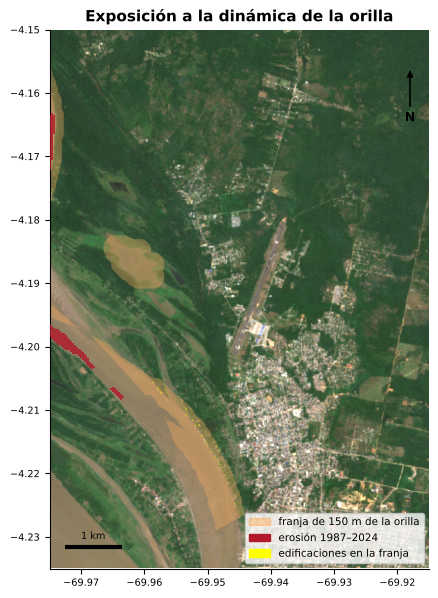

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 7))
viz.fondo(ax, "bbox_urbano")
gpd.GeoSeries([zona_orilla], crs=aoi.crs()).to_crs(4326).plot(ax=ax, color="#fdae61", alpha=0.35, zorder=2)
if not pol_erosion.empty:
    pol_erosion.to_crs(4326).plot(ax=ax, color=viz.ROJO, alpha=0.8, zorder=3)
edif[edif.en_orilla].to_crs(4326).plot(ax=ax, color="yellow", linewidth=0, zorder=4)
ax.legend(handles=[Patch(color="#fdae61", alpha=0.5, label=f"franja de {franja} m de la orilla"), Patch(color=viz.ROJO, label="erosión 1987–2024"),
                   Patch(color="yellow", label="edificaciones en la franja")], loc="lower right", fontsize=7.5, frameon=True)
viz.marco(ax, "bbox_urbano", "Exposición a la dinámica de la orilla")

In [5]:
viz.pie(viz.nota_fuente("landsat", "edificaciones"))

*Fuente: USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie); Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey.*

La franja de 150 m detrás de la orilla de aguas bajas es un **criterio de tamizaje** para priorizar estudios
geotécnicos, no una zona de amenaza oficial. La socavación de barrancos (*tierras caídas*) ocurre sobre todo en la
bajada de las aguas, cuando el suelo saturado pierde el soporte del río [@pigcct2022amazonas].

## 2. Riesgo relativo por celda

,n_edif,poblacion
riesgo_erosion,,
Muy baja,708,"1,546.00"
Baja,1475,"10,011.00"
Media,3579,"29,251.00"
Alta,1038,"5,681.00"
Muy alta,8,19.00


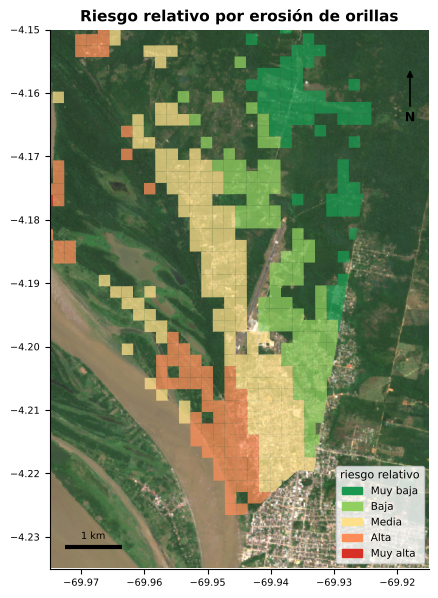

In [6]:
from leticia import riesgo
malla = exposicion.malla_exposicion()
dist_orilla = malla.geometry.centroid.distance(orilla.union_all())
dist_erosion = malla.geometry.centroid.distance(pol_erosion.union_all()) if not pol_erosion.empty else dist_orilla
amenaza_idx = 0.6 * riesgo.normalizar(dist_orilla, invertir=True) + 0.4 * riesgo.normalizar(dist_erosion, invertir=True)
malla["amenaza_erosion"] = riesgo.clasificar(amenaza_idx)
expo = riesgo.normalizar(malla["densidad_construida"]) * 0.5 + riesgo.normalizar(malla["poblacion"]) * 0.5
malla["riesgo_erosion"] = riesgo.matriz_riesgo(malla["amenaza_erosion"], riesgo.clasificar(expo.where(malla.n_edif > 0)))
con = malla[malla.n_edif > 0]
fig, ax = plt.subplots(figsize=(6.4, 7))
viz.mapa_celdas(con, "riesgo_erosion", ax=ax, categorias=riesgo.CLASES, colores=riesgo.COLORES_CLASES, etiqueta="riesgo relativo",
                titulo="Riesgo relativo por erosión de orillas")
display(con.groupby("riesgo_erosion", observed=False)[["n_edif", "poblacion"]].sum().round(0))
pd.DataFrame({"dist_orilla_m": dist_orilla, "riesgo_erosion": malla["riesgo_erosion"]}).to_csv(fuentes.ruta("riesgo_erosion_celdas.csv"))

## 3. Acceso al río: agua frente a la ciudad

In [7]:
frente = urbana.buffer(500).difference(urbana.geometry.iloc[0]).to_crs(4326)
filas = []
for anio in anios:
    m, _ = agua_anio(anio)
    v = m.astype(float).rio.clip(frente.geometry, drop=True)
    filas.append({"año": anio, "agua en la franja de 500 m (ha)": float(np.nansum(v.values)) * PIX_HA})
tab = pd.DataFrame(filas).set_index("año")
nivel = fuentes.nivel_rio()
ventanas = {a: ([a - 1, a, a + 1] if a < 2000 else [a]) for a in tab.index}
tab["nivel medio ago–nov en Leticia (m)"] = [nivel[nivel.index.year.isin(ventanas[a]) & nivel.index.month.isin(pe["meses_aguas_bajas"])].mean() / 100
                                             for a in tab.index]
display(tab.round(1))

,agua en la franja de 500 m (ha),nivel medio ago–nov en Leticia (m)
año,,
1987,365.50,8.50
2001,346.70,10.70
2013,360.10,10.30
2024,245.60,4.70


**Lectura.** La superficie de agua frente a la ciudad en aguas bajas depende del nivel del río y de la forma del
cauce. Cuando dos años tienen niveles parecidos, la diferencia de superficie refleja la sedimentación. La pérdida
de acceso al canal navegable convierte la dinámica fluvial en un riesgo para el abastecimiento de toda la ciudad
([3.2](../32_sequia/index.md)).

## 4. Rondas hídricas, planicie aluvial y ecosistemas acuáticos (SINCHI)

El Instituto SINCHI identifica las **áreas prioritarias de restauración en rondas hídricas**: la planicie aluvial y
los drenajes de la Amazonia colombiana cuya cobertura natural fue reemplazada. Describe cada área por su posición
(planicie aluvial, drenaje) y su cobertura actual, incluidos los barrios construidos sobre la planicie. También
cartografía los **ecosistemas** y separa los acuáticos de aguas blancas, cargadas de sedimentos andinos (los de la
várzea), de los de aguas negras (los del igapó).

,ha
descr_rest,
Planicie aluvial con cobertura de Vegetación secundaria o en transición,"6,300.00"
"Planicie aluvial con cobertura de Mosaico de cultivos, pastos y espacios naturales","1,647.00"
Planicie aluvial con cobertura de Tejido urbano continuo,420.00
Planicie aluvial con cobertura de Tejido urbano discontinuo,312.00
Planicie aluvial con cobertura de Mosaico de pastos y cultivos,306.00
Planicie aluvial con cobertura de Pastos limpios,289.00
Drenaje doble con cobertura de Vegetación secundaria o en transición,199.00
Planicie aluvial con cobertura de Aeropuertos,163.00


Planicie aluvial y drenajes priorizados con **tejido urbano**: 742 ha; **5.384 edificaciones** (~42.457 personas) del casco urbano están dentro de esas áreas. Ecosistemas acuáticos en la extensión regional: aguas blancas 15.439 ha; aguas negras 1.343 ha.

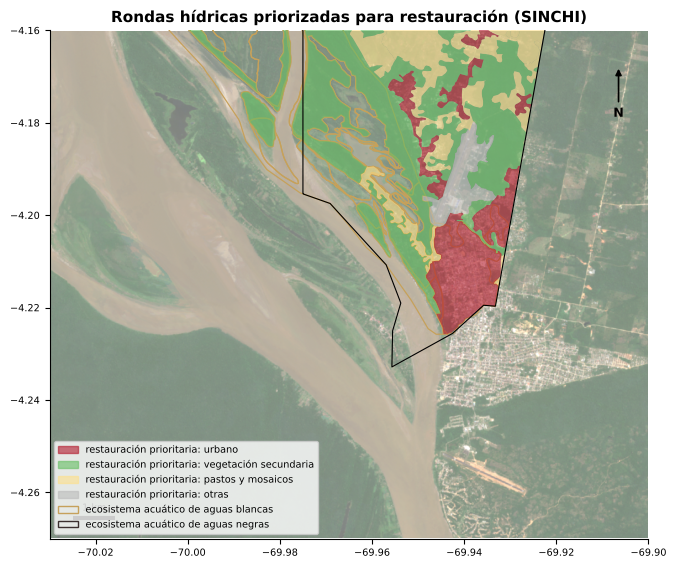

In [8]:
arp = fuentes.siatac("siatac_restauracion_rondas").to_crs(aoi.crs())
eco = fuentes.siatac("siatac_ecosistemas")
urbano_ronda = arp[arp["cobertura"].str.contains("urbano", case=False, na=False)]
edif["en_ronda_urbana"] = pts.within(urbano_ronda.union_all()) if len(urbano_ronda) else False
grupos = {"urbano": "Tejido urbano", "vegetación secundaria": "Vegetación secundaria", "pastos y mosaicos": "Pastos|Mosaico"}
def grupo(c_):
    for k, v in grupos.items():
        if pd.Series([c_]).str.contains(v, case=False, na=False).iloc[0]:
            return k
    return "otras"
arp["grupo"] = arp["cobertura"].map(grupo)
colores_g = {"urbano": viz.ROJO, "vegetación secundaria": "#66bd63", "pastos y mosaicos": "#fee08b", "otras": "#bbbbbb"}
fig, ax = plt.subplots(figsize=(8.6, 6.6))
viz.fondo(ax, "bbox_rio", alfa=0.6)
acuaticos = eco[eco["tipo_ecosistema"].str.contains("acu", case=False, na=False)]
for agua, color in (("Aguas Blancas", "#c6a15b"), ("Aguas Negras", "#3b2f2f")):
    sub = acuaticos[acuaticos["tipo_agua"] == agua]
    if len(sub):
        sub.boundary.plot(ax=ax, color=color, lw=0.9, zorder=2)
for g_, color in colores_g.items():
    sub = arp[arp["grupo"] == g_]
    if len(sub):
        sub.to_crs(4326).plot(ax=ax, color=color, alpha=0.6, lw=0, zorder=3)
urbana.to_crs(4326).boundary.plot(ax=ax, color="k", lw=0.8, zorder=4)
ax.legend(handles=[Patch(color=c_, alpha=0.6, label=f"restauración prioritaria: {g_}") for g_, c_ in colores_g.items()]
          + [Patch(facecolor="none", edgecolor="#c6a15b", label="ecosistema acuático de aguas blancas"),
             Patch(facecolor="none", edgecolor="#3b2f2f", label="ecosistema acuático de aguas negras")], loc="lower left", fontsize=7, frameon=True)
viz.marco(ax, "bbox_rio", "Rondas hídricas priorizadas para restauración (SINCHI)")
area = arp.groupby("descr_rest").apply(lambda x: x.area.sum() / 1e4).sort_values(ascending=False).head(8).rename("ha").to_frame()
display(area.round(0))
agua = acuaticos.groupby("tipo_agua")["area_ha"].sum().round(0)
miles = lambda v: f"{v:,.0f}".replace(",", ".")
display(Markdown(f"Planicie aluvial y drenajes priorizados con **tejido urbano**: {miles(urbano_ronda.area.sum() / 1e4)} ha; "
                 f"**{miles(edif['en_ronda_urbana'].sum())} edificaciones** (~{miles(edif.loc[edif['en_ronda_urbana'], 'poblacion'].sum())} personas) "
                 "del casco urbano están dentro de esas áreas. Ecosistemas acuáticos en la extensión regional: "
                 + "; ".join(f"{k.lower()} {miles(v)} ha" for k, v in agua.items()) + "."))

In [9]:
viz.pie(viz.nota_fuente("siatac_restauracion_rondas", "siatac_ecosistemas", "edificaciones"))

*Fuente: Instituto SINCHI – SIAT-AC — Áreas prioritarias de restauración en rondas hídricas por región (2024), escala 1:100.000; Instituto SINCHI – SIAT-AC — Ecosistemas por región (2024), escala 1:100.000; Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey.*

**Lectura.** A escala 1:100.000, el SINCHI ubica **casi todo el casco urbano** de Leticia sobre la planicie aluvial
del Amazonas y la prioriza, junto con el aeropuerto, para restaurar la vegetación de ronda. La planicie aluvial es
una unidad geomorfológica, no una zona de inundación: la creciente de 100 años alcanza unas 1 740 edificaciones
([3.1.c](../31_inundacion/c_riesgo.ipynb)), no las más de 5 000 que hay sobre la planicie. Lo que la capa muestra es
que la ciudad creció sobre un terreno formado por el río, y que su borde ribereño y sus quebradas son el espacio
natural del río: la base cartográfica oficial para las medidas de prevención y restauración de
[3.3.e](e_medidas.md) y [3.1.e](../31_inundacion/e_medidas.md). Delimitar la ronda en la ciudad exige estudios a
escala de detalle. Los ecosistemas acuáticos de aguas blancas son la várzea del Amazonas, que se inunda cada año
con el pulso del río.